In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.datasets import anes96

df = anes96.load_pandas().data
df = df[["TVnews","PID","age","educ","income","vote"]].copy()
df.shape

(944, 6)

In [2]:
#cleaning the data
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

ranges = {"TVnews":(0,7),"PID":(0,6),"educ":(1,7),"income":(1,24),"vote":(0,1)}
for col,(lo,hi) in ranges.items():
    ok = df[col].between(lo,hi).all()
    print(f"{col:7s} expected {lo}-{hi}, observed {df[col].min():.0f}-{df[col].max():.0f}, all in range: {ok}")
print("Age range:", int(df.age.min()), "to", int(df.age.max()))

print(f"Dole share with repeats {df.vote.mean():.4f}, without {df.drop_duplicates().vote.mean():.4f}")

Missing values: 0
Duplicate rows: 3
TVnews  expected 0-7, observed 0-7, all in range: True
PID     expected 0-6, observed 0-6, all in range: True
educ    expected 1-7, observed 1-7, all in range: True
income  expected 1-24, observed 1-24, all in range: True
vote    expected 0-1, observed 0-1, all in range: True
Age range: 19 to 91
Dole share with repeats 0.4163, without 0.4176


In [3]:
n = len(df)
p = df.vote.mean()
moe = 1.96*np.sqrt(p*(1-p)/n)
print(f"Respondents: {n}")
print(f"Expect to vote Dole:    {p:.1%}  (+/- {moe:.1%} at 95% confidence)")
print(f"Expect to vote Clinton: {1-p:.1%}")

Respondents: 944
Expect to vote Dole:    41.6%  (+/- 3.1% at 95% confidence)
Expect to vote Clinton: 58.4%


In [5]:
df["age_grp"] = pd.cut(df.age,[17,29,44,59,100],labels=["18-29","30-44","45-59","60+"])
df["edu_grp"] = pd.cut(df.educ,[0,3,4,7],labels=["HS or less","Some college","Degree+"])
df["inc_grp"] = pd.cut(df.income,[0,15,20,24],labels=["Low","Mid","High"])
df["news_grp"]= pd.cut(df.TVnews,[-1,1,4,7],labels=["0-1 days","2-4 days","5-7 days"])
df["pid_grp"] = pd.cut(df.PID,[-1,2,3,6],labels=["Dem-leaning","Independent","Rep-leaning"])

rows=[]
for g in ["age_grp","edu_grp","inc_grp","news_grp","pid_grp"]:
    ct = pd.crosstab(df[g],df.vote)
    chi2,pval,_,_ = stats.chi2_contingency(ct)
    for lvl,r in ct.iterrows():
        k=r[1.0]; t=r.sum(); lo,hi=proportion_confint(k,t,method="wilson")
        rows.append([g,lvl,t,k/t,lo,hi,pval])
res = pd.DataFrame(rows,columns=["variable","group","n","dole_share","ci_low","ci_high","chi2_p"])
res_show = res.copy()
for c in ["dole_share","ci_low","ci_high"]: res_show[c]=(res_show[c]*100).round(1)
res_show["chi2_p"]=res_show["chi2_p"].round(4)
res_show

,variable,group,n,dole_share,ci_low,ci_high,chi2_p
0,age_grp,18-29,124,30.6,23.2,39.2,0.0473
1,age_grp,30-44,358,43.6,38.5,48.8,0.0473
2,age_grp,45-59,241,41.1,35.1,47.4,0.0473
3,age_grp,60+,221,45.2,38.8,51.8,0.0473
4,edu_grp,HS or less,313,35.8,30.7,41.2,0.0342
5,edu_grp,Some college,187,43.3,36.4,50.5,0.0342
6,edu_grp,Degree+,444,45.0,40.5,49.7,0.0342
7,inc_grp,Low,342,30.1,25.5,35.2,0.0000
8,inc_grp,Mid,331,45.3,40.0,50.7,0.0000
9,inc_grp,High,271,51.7,45.7,57.5,0.0000


In [6]:
mix = (df.PID>=4).groupby(df.inc_grp,observed=True).mean()
print("Share Rep-leaning, by income band:")
print((mix*100).round(1))

sub = df[df.pid_grp!="Independent"]
within = sub.groupby(["pid_grp","inc_grp"],observed=True).vote.agg(["mean","count"])
within["mean"]=(within["mean"]*100).round(1)
within

Share Rep-leaning, by income band:
inc_grp
Low     32.7
Mid     47.1
High    55.7
Name: PID, dtype: float64


mean  count
pid_grp     inc_grp             
Dem-leaning Low       3.7    217
            Mid       6.0    167
            High      2.9    104
Rep-leaning Low      84.8    112
            Mid      87.2    156
            High     86.1    151

In [7]:
m_a = smf.logit("vote ~ age + educ + income + TVnews", df).fit(disp=0)
m_b = smf.logit("vote ~ age + educ + income + TVnews + PID", df).fit(disp=0)

def tidy(m,name):
    t = pd.DataFrame({"coef":m.params,"p_value":m.pvalues}).drop("Intercept")
    t["model"]=name
    return t
out = pd.concat([tidy(m_a,"without party ID"),tidy(m_b,"with party ID")])
print(out.round(3))
print("Odds ratio per step toward Republican:", round(float(np.exp(m_b.params["PID"])),2))

         coef  p_value             model
age     0.012    0.011  without party ID
educ    0.034    0.453  without party ID
income  0.069    0.000  without party ID
TVnews -0.030    0.277  without party ID
age     0.012    0.135     with party ID
educ    0.015    0.848     with party ID
income  0.031    0.138     with party ID
TVnews  0.010    0.820     with party ID
PID     1.220    0.000     with party ID
Odds ratio per step toward Republican: 3.39


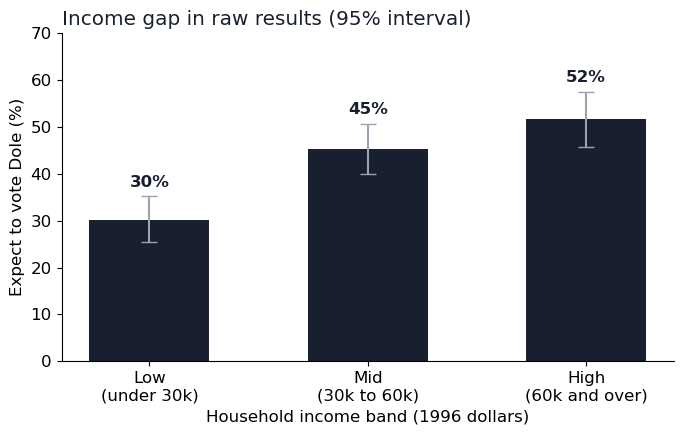

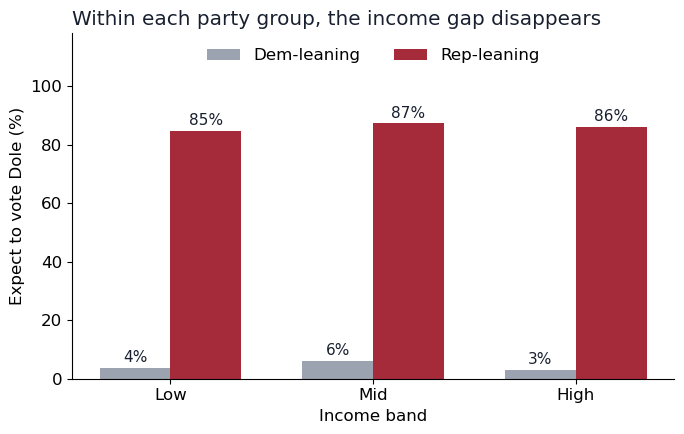

In [8]:
NAVY="#18202F"; RED="#A62B3A"; GREY="#9AA3AF"
plt.rcParams.update({"font.size":12,"axes.spines.top":False,"axes.spines.right":False})

inc = res[res.variable=="inc_grp"]
fig,ax = plt.subplots(figsize=(7,4.5))
x=np.arange(len(inc)); y=inc.dole_share*100
err=[(inc.dole_share-inc.ci_low)*100,(inc.ci_high-inc.dole_share)*100]
ax.bar(x,y,color=NAVY,width=0.55,yerr=err,capsize=6,ecolor=GREY)
for i,(v,hi) in enumerate(zip(y,inc.ci_high*100)):
    ax.text(i,hi+2,f"{v:.0f}%",ha="center",color=NAVY,fontweight="bold")
ax.set_xlabel("Household income band (1996 dollars)")
ax.set_xticks(x); ax.set_xticklabels(["Low\n(under 30k)","Mid\n(30k to 60k)","High\n(60k and over)"])
ax.set_ylabel("Expect to vote Dole (%)"); ax.set_ylim(0,70)
ax.set_title("Income gap in raw results (95% interval)",loc="left",color=NAVY)
plt.tight_layout(); plt.savefig("chart1.png",dpi=160); plt.show()

fig,ax = plt.subplots(figsize=(7,4.5))
w=0.35; labels=["Low","Mid","High"]
dem=[within.loc[("Dem-leaning",l),"mean"] for l in labels]
rep=[within.loc[("Rep-leaning",l),"mean"] for l in labels]
x=np.arange(3)
b1=ax.bar(x-w/2,dem,w,color=GREY,label="Dem-leaning")
b2=ax.bar(x+w/2,rep,w,color=RED,label="Rep-leaning")
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+2,f"{b.get_height():.0f}%",ha="center",fontsize=11,color=NAVY)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_xlabel("Income band")
ax.set_ylabel("Expect to vote Dole (%)"); ax.set_ylim(0,118); ax.legend(frameon=False,ncol=2,loc="upper center")
ax.set_title("Within each party group, the income gap disappears",loc="left",color=NAVY)
plt.tight_layout(); plt.savefig("chart2.png",dpi=160); plt.show()